# Lab 28-10 · Live Checks, Debriefs and Calibration

Companion to [chapter 28-10](../../chapters/28-10-conversation-scenarios.md). Every part asks you to **predict first**, then run. Likelihood ratios and drill parameters are illustrative.

In [1]:
import sys
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import convo as cv

## Part 1 · A follow-up answer

Example 28-10.26: prior 0.4, ratios 3, 2, 0.5, 1, 3; the follow-up on the evasive answer (power at our latency) comes back weak (0.3). The follow-up concerns the same fact as the evasion, so it *replaces* the 0.5 rather than multiplying with it (grouping by cause, 28-06 §3.6).

**Predict:** the posterior after the follow-up.

before follow-up 85.7%, after 78.3% (ratios used: [3, 2, 0.3, 1, 3])


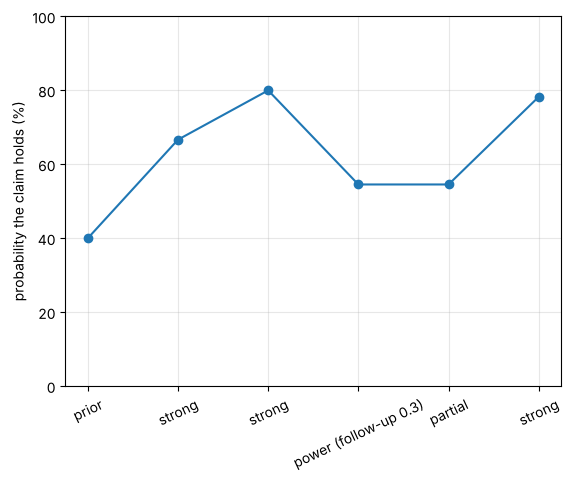

In [2]:
before = cv.debrief(0.4, [(3, 'a'), (2, 'b'), (0.5, 'power'), (1, 'd'), (3, 'e')])
after = cv.debrief(0.4, [(3, 'a'), (2, 'b'), (0.5, 'power'), (1, 'd'), (3, 'e'), (0.3, 'power')])
print(f"before follow-up {100*before[1]:.1f}%, after {100*after[1]:.1f}% (ratios used: {after[2]})")
path = cv.trajectory(0.4, [3, 2, 0.3, 1, 3])
plt.plot(range(len(path)), [100*p for p in path], 'o-')
plt.xticks(range(len(path)), ['prior', 'strong', 'strong', 'power (follow-up 0.3)', 'partial', 'strong'], rotation=25)
plt.ylabel('probability the claim holds (%)'); plt.ylim(0, 100); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · Timed drills

Each drill prints a question; write your answer and time before running the next cell. (The cell below shows a fixed set so the notebook runs unattended.)

**Predict:** how many of 12 you can finish within a minute each.

In [3]:
drills = [cv.drill(seed=k) for k in range(12)]
for k, (q, a, u) in enumerate(drills):
    print(f"{k+1:2d}. {q}")

 1. sleep 2 µA, 2 mA for 5 ms every 5 s: average current?
 2. 51.2 Tb/s at 2 pJ/bit: power?
 3. 1 PFLOP/s, 2 TB/s, batch 16, FP8: decode share of peak?
 4. 51.2 Tb/s at 3 pJ/bit: power?
 5. 25.6 Tb/s at 2 pJ/bit: power?
 6. 50 FIT, 1000000 units, 2000 h/year: failures a year?
 7. 10 FIT, 1000000 units, 8766 h/year: failures a year?
 8. 1000 W out at 96.0% efficiency: loss?
 9. 25.6 Tb/s at 5 pJ/bit: power?
10. sleep 2 µA, 3 mA for 2 ms every 1 s: average current?
11. 10 FIT, 1000000 units, 8766 h/year: failures a year?
12. sleep 2 µA, 3 mA for 2 ms every 1 s: average current?


Write your twelve answers and times now, then run the next cell to score yourself.

In [4]:
for k, (q, a, u) in enumerate(drills):
    print(f"{k+1:2d}. {a:.4g} {u}")

 1. 4 µA
 2. 102.4 W
 3. 6.4 %
 4. 153.6 W
 5. 51.2 W
 6. 100 failures
 7. 87.66 failures
 8. 41.67 W
 9. 128 W
10. 8 µA
11. 87.66 failures
12. 8 µA


## Part 3 · Calibration

**Predict:** the Brier score of a forecaster who said 0.8 on five true claims and 0.6 on five false ones.

In [5]:
f1 = [0.8]*5 + [0.6]*5; o1 = [1]*5 + [0]*5
print(f"first {cv.brier(f1, o1):.2f}; always 0.5 {cv.brier([0.5]*10, o1):.2f}; overconfident {cv.brier([0.95]*10, [1]*6 + [0]*4):.4f}")

first 0.20; always 0.5 0.25; overconfident 0.3625


## Part 4 · Shared causes

**Predict:** the posterior if the two ratios of 3 in Example 28-10.26 come from the same fact.

In [6]:
indep = cv.debrief(0.4, [(3, 'a'), (2, 'b'), (0.5, 'c'), (1, 'd'), (3, 'e')])
shared = cv.debrief(0.4, [(3, 'a'), (2, 'b'), (0.5, 'c'), (1, 'd'), (3, 'a')])
print(f"independent: {100*indep[1]:.1f}%  shared cause counted once: {100*shared[1]:.1f}%")

independent: 85.7%  shared cause counted once: 66.7%
